# Lab 11 Walkthrough: From a Line to Spatial Regression

**Goal.** Fit a regression of Airbnb prices step by step: one predictor by hand, many predictors with a package, then
check whether the errors depend on location, and fix that with spatial regression models. The graded tasks are in
`lab11-tasks.ipynb`. Cells marked **🔎 Try it yourself** are not graded.

**Parts**

0. Setup
1. The data: San Diego Airbnb listings
2. Simple regression by hand
3. Testing the slope and R-squared
4. Many predictors and dummy variables
5. Do the residuals depend on location?
6. Location columns and fixed effects
7. Spatial lag, spatial error and SLX models
8. Choosing a model, and geographically weighted regression

Random numbers (shuffles) use fixed seeds so your numbers match the answer key.

## Part 0. Setup

The next cell prints the versions of the packages. `mgwr` (geographically weighted regression) is installed for you if it is missing.

In [1]:
import sys, subprocess, warnings
from importlib.metadata import version
warnings.filterwarnings("ignore")
try:
    import mgwr                           # geographically weighted regression, used in Part 8
except ImportError:                       # not installed in this kernel yet
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mgwr"])
    import mgwr
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
import spreg
from scipy import stats
from libpysal import weights
from libpysal.weights import lag_spatial
from esda import Moran, Moran_Local

print("Python", sys.version.split()[0], "| geopandas", gpd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__)
print("spreg", version("spreg"), "| esda", version("esda"), "| libpysal", version("libpysal"),
      "| mgwr", version("mgwr"), "| statsmodels", version("statsmodels"))

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 751.6 kB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for spglm: filename=spglm-1.0.8-py3-none-any.whl size=38785 sha256=11f38ce2717782c8dfa638ee08726d1764a3f25ae3711a92f148d035dcca705a
  Stored in directory: /home/jovyan/.cache/pip/wheels/04/56/0d/aaa8d7c0dedde9ad7cdb5882229ed287aacd78b1e648b5b7a1
Successfully built spglm
Python 3.8.16 | geopandas 0.13.2 | numpy 1.24.3 | matplotlib 3.7.1
spreg 1.5.0 | esda 2.5.1 | libpysal 4.8.1 | mgwr 2.2.1 | statsmodels 0.14.0


The helper cell defines the list `X` of the ten predictors and four small functions used all lab:
`blank` (map style), `point_map` (colored dots), `coef_table` (coefficients as a table) and `moran_of` (Moran's I with a seed).

In [2]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D

PURPLE, MAGENTA, BLUE, GRAY = "#7C3AED", "#DB2777", "#2563EB", "#6B6478"
SEQ = LinearSegmentedColormap.from_list("seq", ["#F5F3FB", "#C4B5FD", PURPLE, MAGENTA])
DIV = LinearSegmentedColormap.from_list("div", [BLUE, "#F5F3FB", MAGENTA])
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

# The ten predictors used in the lecture: guests, bathrooms, bedrooms, beds, room type, property type
X = ["accommodates", "bathrooms", "bedrooms", "beds", "rt_Private_room", "rt_Shared_room",
     "pg_Condominium", "pg_House", "pg_Other", "pg_Townhouse"]


def blank(ax):
    """Map style: no ticks, no frame, equal aspect."""
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    for s in ax.spines.values():
        s.set_visible(False)


def point_map(ax, gdf, values, cmap, norm, title, s=7):
    """Listings as colored dots. gdf needs columns px and py (meters)."""
    ax.scatter(gdf["px"], gdf["py"], c=values, cmap=cmap, norm=norm, s=s, alpha=0.85, linewidths=0)
    ax.set_title(title)
    blank(ax)


def coef_table(m, names):
    """Coefficients, standard errors and p-values of a spreg model, as a table (constant first)."""
    k = len(names)
    stat = m.t_stat if hasattr(m, "t_stat") else m.z_stat      # OLS reports t, the GMM models report z
    return pd.DataFrame({"coef": np.ravel(m.betas)[:k], "se": np.ravel(m.std_err)[:k],
                         "p": [t[1] for t in stat][:k]}, index=names)


def pfmt(p):
    """p-value as text: tiny values are shown as p < 0.001."""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


def moran_of(u, w, perms=999, seed=0):
    """Moran's I of a vector u under weights w, with a fixed seed so the p-value repeats."""
    np.random.seed(seed)
    return Moran(np.ravel(u), w, permutations=perms)

## Part 1. The data: San Diego Airbnb listings

- **Source:** Inside Airbnb, a project that publishes the public information on Airbnb listing pages. This extract is dated 7 July 2016. It is the file used in Rey, Arribas-Bel and Wolf (2023), *Geographic Data Science with Python*, chapter "Spatial Regression". Inside Airbnb data are licensed CC BY 4.0.
- **One row** is one listing, a point. Airbnb shifts each location by up to about 150 m.
- **Outcome:** `price` in US dollars per night, and `log_price`, its natural logarithm.
- **Predictors:** `accommodates` (guests), `bathrooms`, `bedrooms`, `beds`; room type (`rt_Private_room`, `rt_Shared_room`; the baseline is the entire home); property type (`pg_Condominium`, `pg_House`, `pg_Other`, `pg_Townhouse`; the baseline is the apartment).
- **Place:** `neighborhood` (45 names), `coastal` (1 for the seven coastal neighborhoods), `d2balboa` (distance to Balboa Park, km), `pool` (1 if the listing mentions a pool).

Locations are stored as longitude and latitude. We project them to meters (EPSG:32611) because neighbors and distances need meters.

In [3]:
db = gpd.read_file("data/regression_db.geojson")
print(db.crs, db.shape)
db = db.to_crs(32611)                         # UTM zone 11N, meters: needed for distances and neighbors
db["px"], db["py"] = db.geometry.x, db.geometry.y
y = db[["log_price"]].values                  # the outcome as a column

EPSG:4326 (6110, 20)


In [4]:
print(db[["price", "log_price", "accommodates", "bathrooms", "bedrooms", "beds"]].describe().round(2))
print("share coastal:", round(db["coastal"].mean(), 3), "| share with a pool:", round(db["pool"].mean(), 3))

         price  log_price  accommodates  bathrooms  bedrooms     beds
count  6110.00    6110.00       6110.00    6110.00   6110.00  6110.00
mean    215.97       5.00          4.22       1.48      1.59     2.20
std     277.55       0.81          2.84       0.86      1.14     1.71
min      18.00       2.89          1.00       0.00      0.00     0.00
25%      85.00       4.44          2.00       1.00      1.00     1.00
50%     139.00       4.93          4.00       1.00      1.00     2.00
75%     250.00       5.52          6.00       2.00      2.00     3.00
max    4900.00       8.50         21.00      10.00     10.00    16.00
share coastal: 0.377 | share with a pool: 0.195


**Map of price.** Colors are quintiles: five groups with the same number of listings. The class limits are listed below the map.

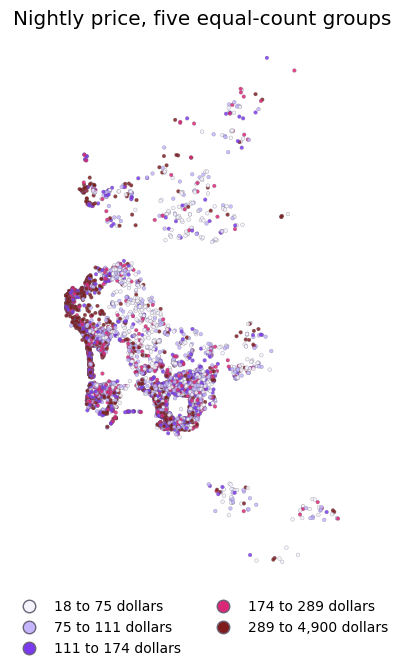

In [5]:
qs = np.quantile(db["price"], [0, .2, .4, .6, .8, 1])
cls = np.digitize(db["price"], qs[1:-1])
cols = ["#F5F3FB", "#C4B5FD", "#7C3AED", "#DB2777", "#7F1D1D"]
fig, ax = plt.subplots(figsize=(6, 7.2))
ax.scatter(db["px"], db["py"], c=[cols[c] for c in cls], s=7, alpha=0.85, linewidths=0.2, edgecolors=GRAY)
blank(ax)
ax.set_title("Nightly price, five equal-count groups")
labels = [f"{qs[i]:,.0f} to {qs[i + 1]:,.0f} dollars" for i in range(5)]
ax.legend(handles=[Line2D([0], [0], marker="o", ls="", mfc=c, mec=GRAY, ms=9, label=l) for c, l in zip(cols, labels)],
          loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False, fontsize=10)
plt.show()

**Why log price?** Prices have a long right tail. The logarithm pulls the tail in, and a coefficient on the log scale reads as a percent change.

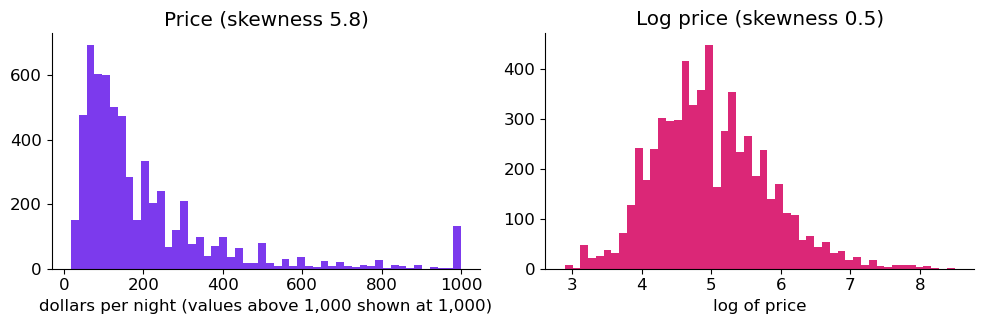

In [6]:
def skew(v):
    return ((v - v.mean()) ** 3).mean() / v.std() ** 3

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(db["price"].clip(upper=1000), bins=50, color=PURPLE)
axes[0].set_title(f"Price (skewness {skew(db['price']):.1f})")
axes[0].set_xlabel("dollars per night (values above 1,000 shown at 1,000)")
axes[1].hist(db["log_price"], bins=50, color=MAGENTA)
axes[1].set_title(f"Log price (skewness {skew(db['log_price']):.1f})")
axes[1].set_xlabel("log of price")
plt.tight_layout()
plt.show()

**🔎 Try it yourself.** Which neighborhood has the most listings? Which has the highest median price? (`db["neighborhood"].value_counts()` and `db.groupby("neighborhood")["price"].median()`.)

## Part 2. Simple regression by hand

A regression of the outcome $y$ on one predictor $x$ fits a line

$$y_i=\beta_0+\beta_1 x_i+\varepsilon_i$$

- $y_i$: log price of listing $i$; $x_i$: its number of bedrooms
- $\beta_0$: intercept, the line's height at $x=0$; $\beta_1$: slope, the change in $y$ for one more unit of $x$
- $\varepsilon_i$: error, what the line misses for listing $i$

**Ordinary least squares** chooses the $\beta$ values that make the sum of squared errors smallest. For one predictor the answer has a formula:

$$\hat\beta_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x$$

- $\bar x,\bar y$: the means of $x$ and $y$; the hats mark estimates

In [7]:
x = db["bedrooms"].values.astype(float)
yy = db["log_price"].values
b1 = ((x - x.mean()) * (yy - yy.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = yy.mean() - b1 * x.mean()
print(f"by the formula: intercept {b0:.3f}, slope {b1:.3f}")
print("np.polyfit     :", np.round(np.polyfit(x, yy, 1)[::-1], 3), "(intercept, slope)")

by the formula: intercept 4.239, slope 0.476
np.polyfit     : [4.239 0.476] (intercept, slope)


**Reading the numbers.** The slope is on the log scale. One more bedroom multiplies the price by $e^{\hat\beta_1}$. The intercept is the predicted log price at 0 bedrooms (a studio).

one more bedroom multiplies the price by 1.61, about 61% more
predicted price of a studio: 69 dollars


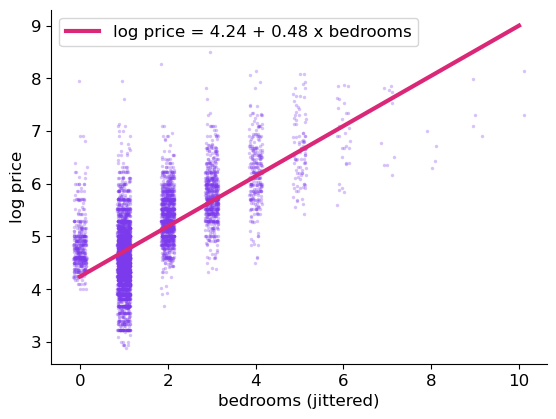

In [8]:
print(f"one more bedroom multiplies the price by {np.exp(b1):.2f}, about {np.exp(b1) - 1:.0%} more")
print(f"predicted price of a studio: {np.exp(b0):.0f} dollars")
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.scatter(x + rng.uniform(-.15, .15, len(x)), yy, s=6, color=PURPLE, alpha=0.3, linewidths=0)
xs = np.array([0, x.max()])
ax.plot(xs, b0 + b1 * xs, color=MAGENTA, lw=3, label=f"log price = {b0:.2f} + {b1:.2f} x bedrooms")
ax.set_xlabel("bedrooms (jittered)")
ax.set_ylabel("log price")
ax.legend()
plt.show()

**🔎 Try it yourself.** Repeat the formula with `accommodates` as the predictor. Is the slope larger or smaller than for bedrooms?

## Part 3. Testing the slope and R-squared

The **null hypothesis** $H_0$ says the slope is zero: bedrooms say nothing about price, and the best line is flat at the mean. The **alternative** $H_a$ says the slope is not zero. A sample's slope is never exactly zero even when $H_0$ is true, so we ask how far from zero it is in units of its own wobble, the **standard error** (SE).

$$t=\frac{\hat\beta_1}{\mathrm{SE}(\hat\beta_1)},\qquad \mathrm{SE}(\hat\beta_1)=\sqrt{\frac{\mathrm{SSE}/(n-2)}{\sum_i(x_i-\bar x)^2}}$$

- $\mathrm{SSE}=\sum_i(y_i-\hat y_i)^2$: sum of squared errors of the fitted line; $n-2$ because two numbers were estimated
- The **p-value** is the probability of a $t$ at least this far from zero if $H_0$ were true

In [9]:
n = len(x)
fitted = b0 + b1 * x
sse = ((yy - fitted) ** 2).sum()
se = np.sqrt(sse / (n - 2) / ((x - x.mean()) ** 2).sum())
t = b1 / se
p = 2 * stats.t.sf(abs(t), n - 2)
print(f"SE = {se:.4f}, t = {t:.1f}, {pfmt(p)}")

check = sm.OLS(yy, sm.add_constant(x)).fit()     # statsmodels gives the same numbers
print(f"statsmodels: t = {check.tvalues[1]:.1f}, {pfmt(check.pvalues[1])}")

SE = 0.0067, t = 70.5, p < 0.001
statsmodels: t = 70.5, p < 0.001


**R-squared** compares the line's misses with the misses of the simplest rule, predicting the mean every time:

$$R^2=1-\frac{\mathrm{SS}_{res}}{\mathrm{SS}_{tot}}$$

- $\mathrm{SS}_{res}=\sum_i(y_i-\hat y_i)^2$: squared misses around the line; $\mathrm{SS}_{tot}=\sum_i(y_i-\bar y)^2$: squared misses around the mean
- 0 means no better than the mean; 1 means no misses

In [10]:
ss_tot = ((yy - yy.mean()) ** 2).sum()
print(f"SS_tot = {ss_tot:,.0f}, SS_res = {sse:,.0f}, R2 = {1 - sse / ss_tot:.3f}")
print(f"the same as the squared correlation: {np.corrcoef(x, yy)[0, 1] ** 2:.3f}")

SS_tot = 3,980, SS_res = 2,193, R2 = 0.449
the same as the squared correlation: 0.449


A small p-value says the slope is probably not zero. It does not say the slope matters. With 6,110 listings even a tiny effect is significant, so look at the size of the slope and at $R^2$ too.

**🔎 Try it yourself.** Find a single predictor in `X` that is significant (p below 0.001) but has an $R^2$ below 0.01. (`pg_House` is one.)

## Part 4. Many predictors and dummy variables

With $p$ predictors the model is $\mathbf{y}=\mathbf{X}\boldsymbol\beta+\boldsymbol\varepsilon$ and the least-squares answer is $\hat{\boldsymbol\beta}=(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$.

- $\mathbf{y}$: the $n$ log prices; $\boldsymbol\varepsilon$: the $n$ errors
- $\mathbf{X}$: an $n\times(p+1)$ table of predictors with a first column of ones for $\beta_0$; $\boldsymbol\beta$: the $p+1$ coefficients
- $\mathbf{X}^\top$: rows and columns swapped; $(\cdot)^{-1}$: matrix inverse

A **dummy variable** is 1 if a listing is in a category and 0 if not. One category is left out as the **baseline**, and each coefficient is a difference from it. If every category had a dummy and the model also had an intercept, the dummies would add up to the column of ones, $\mathbf{X}^\top\mathbf{X}$ could not be inverted, and the coefficients would not be unique.

We use `spreg.OLS` from the PySAL package `spreg`. It returns coefficients, tests and diagnostics.

In [11]:
m1 = spreg.OLS(y, db[X].values, name_y="log_price", name_x=X)
print(f"R2 = {m1.r2:.3f}, n = {m1.n}")
tab = coef_table(m1, ["constant"] + X)
tab["percent change"] = (np.exp(tab["coef"]) - 1) * 100
tab.loc["constant", "percent change"] = np.nan   # the constant is a baseline level, not a change
print(tab.round(3))

R2 = 0.668, n = 6110
                  coef     se      p  percent change
constant         4.388  0.016  0.000             NaN
accommodates     0.083  0.005  0.000           8.703
bathrooms        0.192  0.011  0.000          21.213
bedrooms         0.153  0.011  0.000          16.477
beds            -0.042  0.007  0.000          -4.086
rt_Private_room -0.551  0.016  0.000         -42.345
rt_Shared_room  -1.238  0.038  0.000         -71.013
pg_Condominium   0.144  0.022  0.000          15.446
pg_House        -0.010  0.015  0.470          -1.043
pg_Other         0.141  0.023  0.000          15.160
pg_Townhouse    -0.042  0.034  0.224          -4.081


**Reading the table.** Holding the other predictors fixed, a coefficient is the change in log price for one more unit of that predictor. For a dummy it is the difference from the baseline. `percent change` is $100(e^{\beta}-1)$.

In [12]:
u = m1.u.flatten()                              # residuals: observed minus predicted log price
print(f"condition number (near-copies among predictors): {m1.mulColli:.1f}")
print(f"Jarque-Bera test of normal errors: statistic {m1.jarque_bera['jb']:.0f}, {pfmt(m1.jarque_bera['pvalue'])}")
print(f"Breusch-Pagan test of equal spread: statistic {m1.breusch_pagan['bp']:.0f}, {pfmt(m1.breusch_pagan['pvalue'])}")

condition number (near-copies among predictors): 12.0
Jarque-Bera test of normal errors: statistic 2672, p < 0.001
Breusch-Pagan test of equal spread: statistic 323, p < 0.001


OLS assumes the relationship is linear, the error spread is constant, the errors are roughly normal, the predictors are not near-copies of each other, and **the errors are independent**. The first four have standard checks and fixes. The rest of the lab is about the fifth.

**🔎 Try it yourself.** Drop `beds` from the model. Does the coefficient on `accommodates` change? Why might it?

## Part 5. Do the residuals depend on location?

A **residual** is the observed value minus the predicted value. If the model has captured everything that matters, residuals should look like noise on the map.

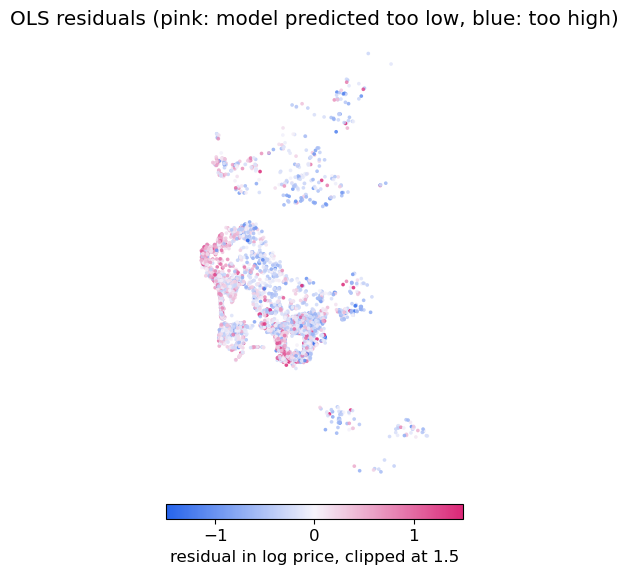

In [13]:
lim = 1.5
norm = Normalize(-lim, lim)
fig, ax = plt.subplots(figsize=(6.4, 7.2))
point_map(ax, db, np.clip(u, -lim, lim), DIV, norm, "OLS residuals (pink: model predicted too low, blue: too high)")
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=DIV, norm=norm), ax=ax, shrink=0.6, pad=0.02, orientation="horizontal")
cb.set_label("residual in log price, clipped at 1.5")
plt.show()

**Spatial weights.** A weights matrix $W$ has one row and one column per listing. Entry $w_{ij}>0$ if $j$ counts as a neighbor of $i$. We use the **20 nearest neighbors** (`libpysal.weights.KNN`) and **row standardization**, which makes each row sum to 1, so $W$ times a variable is a mean over the neighbors.

The **spatial lag** of a variable $z$ at listing $i$ is $(Wz)_i=\sum_j w_{ij}z_j$: the mean of $z$ over the 20 nearest listings.

In [14]:
w20 = weights.KNN.from_dataframe(db, k=20)    # each listing's 20 nearest listings
w20.transform = "R"                           # row-standardize: every row sums to 1
print(w20.n, "listings,", w20.mean_neighbors, "neighbors each, weight", w20.weights[0][0])

6110 listings, 20.0 neighbors each, weight 0.05


In [15]:
lag_price = lag_spatial(w20, db["log_price"].values)
print(f"listing 0: log price {db['log_price'][0]:.2f}, lag {lag_price[0]:.2f}")
print(f"correlation of log price with its lag: {np.corrcoef(db['log_price'], lag_price)[0, 1]:.2f}")
d = [np.hypot(db.px[j] - db.px[0], db.py[j] - db.py[0]) for j in w20.neighbors[0]]
print(f"listing 0 has neighbors between {min(d):.0f} and {max(d):.0f} m away")

listing 0: log price 6.05, lag 4.54
correlation of log price with its lag: 0.51
listing 0 has neighbors between 100 and 300 m away


**Moran's I** measures whether similar values sit near each other:

$$I=\frac{n}{\sum_i\sum_j w_{ij}}\cdot\frac{\sum_i\sum_j w_{ij}(z_i-\bar z)(z_j-\bar z)}{\sum_i(z_i-\bar z)^2}$$

- $z_i$: the residual of listing $i$; $\bar z$: the mean residual
- With row-standardized $W$, $I$ is the slope of the lag against the value (the Moran scatterplot). No pattern gives $I\approx0$
- **Pseudo p-value:** shuffle the residuals among the listings 999 times and recompute $I$. The p-value is the share of shuffles with $I$ at least as large as the observed one

Moran's I of the residuals = 0.140, pseudo p-value = 0.001
expected under no pattern -0.0002; largest I among 999 shuffles = 0.012


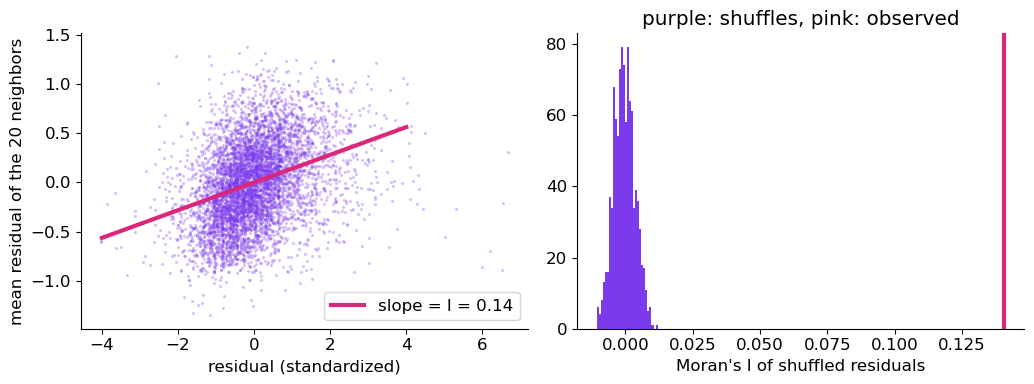

In [16]:
mi = moran_of(u, w20)
print(f"Moran's I of the residuals = {mi.I:.3f}, pseudo p-value = {mi.p_sim:.3f}")
print(f"expected under no pattern {mi.EI:.4f}; largest I among 999 shuffles = {mi.sim.max():.3f}")

z = (u - u.mean()) / u.std()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].scatter(z, lag_spatial(w20, z), s=5, color=PURPLE, alpha=0.3, linewidths=0)
xs = np.array([-4, 4])
axes[0].plot(xs, mi.I * xs, color=MAGENTA, lw=3, label=f"slope = I = {mi.I:.2f}")
axes[0].set_xlabel("residual (standardized)")
axes[0].set_ylabel("mean residual of the 20 neighbors")
axes[0].legend()
axes[1].hist(mi.sim, bins=30, color=PURPLE)
axes[1].axvline(mi.I, color=MAGENTA, lw=3)
axes[1].set_xlabel("Moran's I of shuffled residuals")
axes[1].set_title("purple: shuffles, pink: observed")
plt.tight_layout()
plt.show()

The residuals cluster, so the independence assumption fails. **Local Moran's I** says where: $I_i=z_i\sum_j w_{ij}z_j$ with $z$ standardized. A listing is **high-high** if its residual and its neighbors' residuals are both high (the model under-predicts there), **low-low** if both are low (over-predicts). Listings are marked when the pseudo p-value is below 0.01.

With 6,110 tests, about 61 would pass by chance.

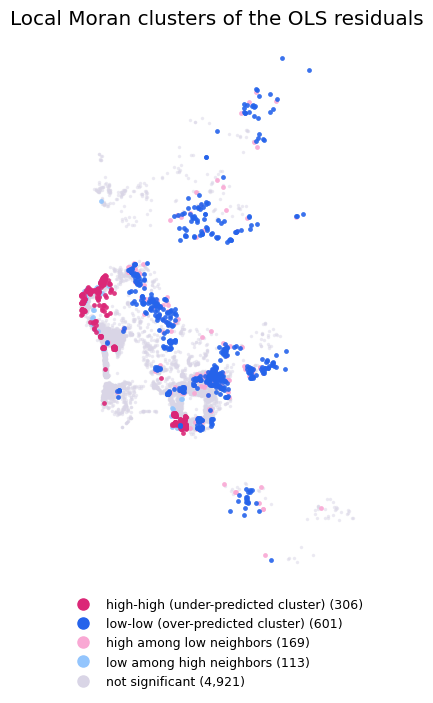

share of high-high listings that are coastal: 0.64
share of low-low listings that are coastal: 0.01


In [17]:
np.random.seed(0)
lisa = Moran_Local(u, w20, permutations=999)
sig = lisa.p_sim < 0.01
cat = np.where(~sig, 0, lisa.q)                  # q: 1 high-high, 2 low-high, 3 low-low, 4 high-low
names = {0: "not significant", 1: "high-high (under-predicted cluster)", 3: "low-low (over-predicted cluster)",
         2: "low among high neighbors", 4: "high among low neighbors"}
cols = {0: "#D9D5E6", 1: MAGENTA, 3: BLUE, 2: "#93C5FD", 4: "#F9A8D4"}
fig, ax = plt.subplots(figsize=(6.4, 7.2))
for c in (0, 2, 4, 1, 3):
    m = cat == c
    ax.scatter(db["px"][m], db["py"][m], c=cols[c], s=6 if c == 0 else 12, alpha=0.5 if c == 0 else 0.9, linewidths=0)
blank(ax)
ax.set_title("Local Moran clusters of the OLS residuals")
ax.legend(handles=[Line2D([0], [0], marker="o", ls="", color=cols[c], ms=8, label=f"{names[c]} ({(cat == c).sum():,})")
                   for c in (1, 3, 4, 2, 0)], loc="upper center", bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=9)
plt.show()
print("share of high-high listings that are coastal:", round(db["coastal"].values[cat == 1].mean(), 2))
print("share of low-low listings that are coastal:", round(db["coastal"].values[cat == 3].mean(), 2))

**Note on counts.** The lecture slides were built with a newer version of `esda` than this environment, and the number of marked listings differs between versions even with the same data and rule. Use the counts you get here.

**🔎 Try it yourself.** Rebuild the weights with `k=10` and recompute Moran's I of the residuals. Does it go up or down?

## Part 6. Location columns and fixed effects

**Location columns.** A first idea is to add a location column: distance to a point, or longitude and latitude.

In [18]:
def fit_and_test(cols, label):
    m = spreg.OLS(y, db[cols].values, name_x=cols)
    mi_ = moran_of(m.u, w20)
    print(f"{label:34s} R2 = {m.r2:.3f}   Moran's I of residuals = {mi_.I:.3f}")
    return m

ll = db.to_crs(4326)
db["lon"], db["lat"] = ll.geometry.x.values, ll.geometry.y.values
base = fit_and_test(X, "OLS")
m_d = fit_and_test(X + ["d2balboa"], "OLS + distance to Balboa Park")
fit_and_test(X + ["lon", "lat"], "OLS + longitude and latitude")
print(f"d2balboa coefficient {m_d.betas[-1][0]:.4f}, p = {m_d.t_stat[-1][1]:.3f}")

OLS                                R2 = 0.668   Moran's I of residuals = 0.140
OLS + distance to Balboa Park      R2 = 0.669   Moran's I of residuals = 0.140
OLS + longitude and latitude       R2 = 0.686   Moran's I of residuals = 0.105
d2balboa coefficient 0.0016, p = 0.089


A distance to one point assumes one center, and longitude and latitude fit a smooth tilt. Neither lets neighbors depend on each other. One way to let place change the model:

**Spatial fixed effects** give each neighborhood its own intercept: $y_i=\alpha_{g(i)}+\beta_1x_{i1}+\dots+\beta_px_{ip}+\varepsilon_i$, where $g(i)$ is the neighborhood of listing $i$ and $\alpha_g$ is that neighborhood's price level. The slopes stay the same everywhere. We use `statsmodels` with one dummy per neighborhood and no separate intercept.

In [19]:
dm = pd.get_dummies(db["neighborhood"]).astype(float)
fe = sm.OLS(db["log_price"], pd.concat([db[X], dm], axis=1)).fit()
print(f"R2 = {fe.rsquared:.3f} (OLS {base.r2:.3f}); Moran's I of residuals = {moran_of(fe.resid.values, w20).I:.3f}")
alpha = fe.params[dm.columns].sort_values()
print("lowest intercepts: ", alpha.head(3).round(2).to_dict())
print("highest intercepts:", alpha.tail(3).round(2).to_dict())

R2 = 0.712 (OLS 0.668); Moran's I of residuals = 0.036
lowest intercepts:  {'North Clairemont': 3.98, 'Mira Mesa': 3.99, 'College Area': 4.03}
highest intercepts: {'La Jolla': 4.68, 'Core': 4.73, 'Gaslamp Quarter': 4.78}


## Part 7. Spatial lag, spatial error and SLX models

Three stories about why neighbors are alike:

| Idea | Model | Equation |
|---|---|---|
| Neighbors' characteristics matter | **SLX** | $y_i=\beta_0+\sum_k\beta_kx_{ik}+\sum_m\gamma_m(WX_m)_i+\varepsilon_i$ |
| Neighbors' prices matter | **Spatial lag** | $y=\rho Wy+X\beta+\varepsilon$ |
| Neighbors share unmeasured factors | **Spatial error** | $y=X\beta+u,\ u=\lambda Wu+\varepsilon$ |

Terms: $(WX_m)_i$ is the mean of predictor $m$ over the neighbors of $i$ and $\gamma_m$ its effect; $Wy$ is the mean price of the neighbors and $\rho$ how strongly it carries into the listing's price; $u$ is the total error, $Wu$ the mean error of the neighbors, $\lambda$ how strongly errors follow neighbors' errors, and $\varepsilon$ the leftover independent error.

**SLX** adds the spatial lags of some predictors to ordinary least squares. We lag the property-type dummies.

In [20]:
PG = ["pg_Condominium", "pg_House", "pg_Other", "pg_Townhouse"]
for c in PG:
    db["w_" + c] = lag_spatial(w20, db[c].values)
slx_cols = X + ["w_" + c for c in PG]
slx = spreg.OLS(y, db[slx_cols].values, name_x=slx_cols)
print(coef_table(slx, ["constant"] + slx_cols).tail(4).round(3))
gamma = slx.betas[slx_cols.index("w_pg_Condominium") + 1][0]
print(f"\napartment to condominium: own log price {slx.betas[X.index('pg_Condominium') + 1][0]:+.3f}; "
      f"each listing counting it as a neighbor {gamma:.3f}/20 = {gamma / 20:+.3f}")

                   coef     se      p
w_pg_Condominium  0.602  0.069  0.000
w_pg_House       -0.078  0.032  0.014
w_pg_Other        0.483  0.055  0.000
w_pg_Townhouse   -0.268  0.122  0.028

apartment to condominium: own log price +0.106; each listing counting it as a neighbor 0.602/20 = +0.030


**Spatial error and spatial lag.** `spreg.GM_Error_Het` fits the error model by the generalized method of moments with heteroskedasticity-robust errors. `spreg.GM_Lag` fits the lag model by two-stage least squares, using the spatial lags of the predictors as instruments. (OLS is biased for the lag model because $Wy$ depends on the neighbors' errors, which depend on this listing's price.)

In [21]:
err = spreg.GM_Error_Het(y, db[X].values, w=w20, name_x=X)
lag = spreg.GM_Lag(y, db[X].values, w=w20, name_x=X)
rho = float(np.ravel(lag.rho)[0])
print(f"error model: lambda = {err.betas[-1][0]:.3f} (SE {err.std_err[-1]:.3f})")
print(f"lag model:   rho    = {rho:.3f} (SE {lag.std_err[-1]:.3f})")

rows = ["bedrooms", "bathrooms", "accommodates"]
cmp_ = pd.DataFrame({"OLS": coef_table(m1, ["constant"] + X).loc[rows, "coef"].values,
                     "SLX": coef_table(slx, ["constant"] + slx_cols).loc[rows, "coef"].values,
                     "Error": coef_table(err, ["constant"] + X + ["lambda"]).loc[rows, "coef"].values,
                     "Lag": coef_table(lag, ["constant"] + X + ["rho"]).loc[rows, "coef"].values}, index=rows)
print(cmp_.round(3))
resid_I = {"OLS": moran_of(u, w20).I, "SLX": moran_of(slx.u, w20).I,
           "Error (filtered)": moran_of(err.e_filtered, w20).I, "Lag": moran_of(lag.u, w20).I}
print("Moran's I of residuals:", {k_: round(v, 3) for k_, v in resid_I.items()})

error model: lambda = 0.643 (SE 0.019)
lag model:   rho    = 0.342 (SE 0.015)
                OLS    SLX  Error    Lag
bedrooms      0.153  0.164  0.174  0.160
bathrooms     0.192  0.189  0.163  0.164
accommodates  0.083  0.082  0.069  0.070
Moran's I of residuals: {'OLS': 0.14, 'SLX': 0.117, 'Error (filtered)': -0.01, 'Lag': 0.027}


The error and lag models remove most of the residual clustering. SLX leaves most of it. The coefficients change somewhat.

**Reading lag-model coefficients.** The reduced form is $y=(I-\rho W)^{-1}(X\beta+\varepsilon)$, and $(I-\rho W)^{-1}=I+\rho W+\rho^2W^2+\dots$: a change in one listing spreads to its neighbors, their neighbors, and so on. If every listing gained a bedroom, the average price would rise by $\beta/(1-\rho)$, the **total effect**, which is larger than $\beta$. The **direct effect** is the change at the listing itself, and the **indirect effect** is the rest.

In [22]:
beta_bed = lag.betas[X.index("bedrooms") + 1][0]
print(f"coefficient on bedrooms {beta_bed:.3f}; total effect {beta_bed / (1 - rho):.3f}")

# Ripple of one listing gaining a bedroom: sum the series I + rho W + rho^2 W^2 + ... applied to a unit change at listing i
i = 0
W_ = w20.sparse
e = np.zeros(w20.n)
e[i] = 1.0
eff, term = e.copy(), e.copy()
for _ in range(30):
    term = rho * (W_ @ term)
    eff += term
eff *= beta_bed
print(f"listing {i} itself: {eff[i]:.3f}; all other listings together: {eff.sum() - eff[i]:.3f}; "
      f"listings changed by more than 0.0001: {(eff > 1e-4).sum()}")

coefficient on bedrooms 0.160; total effect 0.244
listing 0 itself: 0.161; all other listings together: 0.097; listings changed by more than 0.0001: 68


**🔎 Try it yourself.** Change `i` to another listing. Is the ripple larger where listings are dense?

## Part 8. Choosing a model, and geographically weighted regression

**Lagrange multiplier (LM) tests** use the OLS residuals to test for a missing lag term and a missing error term. `spreg.OLS` computes them when you pass the weights and `spat_diag=True`. The robust versions guard against the other kind of dependence.

In [23]:
diag = spreg.OLS(y, db[X].values, w=w20, spat_diag=True, name_x=X)
print(f"LM lag {diag.lm_lag[0]:.0f}, LM error {diag.lm_error[0]:.0f}")
print(f"robust LM lag {diag.rlm_lag[0]:.0f}, robust LM error {diag.rlm_error[0]:.0f}")

LM lag 1127, LM error 1339
robust LM lag 382, robust LM error 593


Both are significant here, so the tests do not choose for us. The robust error statistic is larger, which is a hint and not a rule. Theory comes first: does the price of one listing influence its neighbor's price (lag), or do neighbors share a missing factor (error)?

**Geographically weighted regression (GWR)** fits one regression per location, weighting nearby listings more:

$$y_i=\beta_0(u_i,v_i)+\sum_k\beta_k(u_i,v_i)x_{ik}+\varepsilon_i$$

- $(u_i,v_i)$: the coordinates of listing $i$; each coefficient is a function of place
- Weights come from a kernel that falls with distance to $i$ and reaches 0 at the **bandwidth**. Here the bandwidth is a number of nearest listings, chosen by minimizing AICc, a score that rewards fit and penalizes complexity

We fit four predictors. (A fit with 60 neighbors fails here: in some places the room-type dummy never varies.)

bandwidth: 137 nearest listings; local R2 0.741
global bedrooms coefficient 0.11; local 5th to 95th percentile -0.13 to 0.35


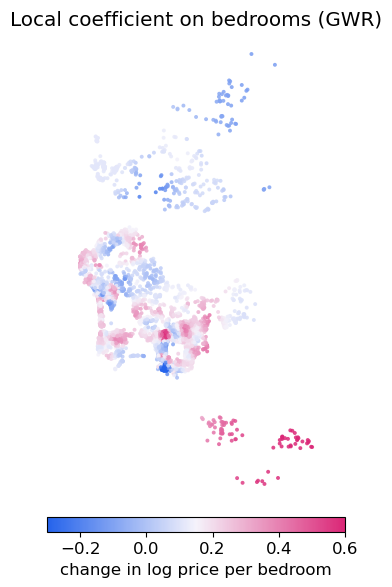

In [24]:
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW

V = ["accommodates", "bathrooms", "bedrooms", "rt_Private_room"]
coords = np.column_stack([db["px"], db["py"]])
bw = Sel_BW(coords, y, db[V].values, fixed=False, kernel="bisquare").search()
gwr = GWR(coords, y, db[V].values, bw, fixed=False, kernel="bisquare").fit()
loc_bed = gwr.params[:, 3]                       # column 0 is the intercept, so bedrooms is column 3
glob = np.linalg.lstsq(np.column_stack([np.ones(len(y)), db[V].values]), y, rcond=None)[0].ravel()
r2_local = 1 - ((y.ravel() - gwr.predy.ravel()) ** 2).sum() / ((y.ravel() - y.mean()) ** 2).sum()   # computed directly
print(f"bandwidth: {bw:.0f} nearest listings; local R2 {r2_local:.3f}")
print(f"global bedrooms coefficient {glob[3]:.2f}; local 5th to 95th percentile {np.percentile(loc_bed, 5):.2f} to {np.percentile(loc_bed, 95):.2f}")

norm = Normalize(-0.3, 0.6)
fig, ax = plt.subplots(figsize=(6.4, 7.4))
point_map(ax, db, loc_bed, DIV, norm, "Local coefficient on bedrooms (GWR)", s=8)
fig.colorbar(plt.cm.ScalarMappable(cmap=DIV, norm=norm), ax=ax, shrink=0.6, pad=0.02, orientation="horizontal").set_label("change in log price per bedroom")
plt.show()

With one fit per listing, GWR is a tool for exploring where a relationship differs. It does not test it. A smaller bandwidth shows more local detail and more noise.

**🔎 Try it yourself.** Refit with a bandwidth of 400 nearest listings (`GWR(coords, y, db[V].values, 400, fixed=False, kernel="bisquare").fit()`) and compare the maps.

## Learn More / Going Further

- **Other weights.** Compare `k = 5, 10, 20, 50` for the Moran's I of the residuals and for the lag parameter. Which would you trust, and what would you check?
- **Spatial Durbin model.** Combine SLX and lag: `spreg.GM_Lag(y, X, w=w20, slx_lags=1)` (if your `spreg` supports `slx_lags`).
- **Regimes and the Chow test.** `spreg.OLS_Regimes(y, X, regimes, constant_regi="many", cols2regi="all", regime_err_sep=False)` fits separate coefficients for each group of places (for example `coastal` or `pool`); `.chow.joint` tests whether the groups' coefficients are equal. Which predictors differ?
- **Multiscale GWR.** `mgwr.gwr.MGWR` lets each predictor have its own bandwidth.
- **Other places.** The same workflow applies to any listing or sales data with a price and coordinates. Which of the three stories (neighbors' characteristics, neighbors' prices, shared errors) would you expect for house sales?
- **Stretch challenge.** Ask whether the lag parameter changes when you add neighborhood fixed effects to the lag model.
- **Reading.** Rey, Arribas-Bel and Wolf (2023), *Geographic Data Science with Python*, "Spatial Regression": https://geographicdata.science/book/notebooks/11_regression.html. Gibbons and Overman (2012), "Mostly pointless spatial econometrics?", *Journal of Regional Science* 52(2), 172-191.